# 03 - Modelling & Evaluation

**Goal:** compare six algorithms under three imbalance strategies, tune the best, pick a business-aware threshold, and check the `PageValues` dependence.

> Training itself is done by `python -m src.models.train`; this notebook reads its outputs so results are reproducible and not re-fitted ad hoc.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import logging; logging.disable(logging.INFO)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.config.settings import get_settings
from src.data.loader import load_dataset
S = get_settings()
df = load_dataset(S)
sns.set_theme(style="whitegrid")
import json
REP = S.path('reports_dir')
comp = pd.read_csv(REP / 'model_comparison.csv')
meta = json.load(open(S.path('artifacts_dir') / 'metadata.json'))

## 1. Benchmark: 6 models x 3 imbalance strategies (5-fold stratified CV on train)

In [2]:
cols = ['model','strategy','tuned','pr_auc','roc_auc','recall','precision','f1','accuracy']
comp[cols].sort_values('pr_auc', ascending=False).round(4).reset_index(drop=True)

,model,strategy,tuned,pr_auc,roc_auc,recall,precision,f1,accuracy
0,catboost,none,True,0.8498,0.9688,0.7548,0.7810,0.7672,0.9280
1,xgboost,none,True,0.8484,0.9682,0.7555,0.7680,0.7614,0.9256
2,catboost,none,False,0.8443,0.9672,0.7528,0.7789,0.7654,0.9275
3,catboost,class_weight,False,0.8433,0.9668,0.8827,0.6475,0.7469,0.9059
4,xgboost,none,False,0.8429,0.9670,0.7462,0.7637,0.7547,0.9238
5,xgboost,class_weight,False,0.8411,0.9662,0.8960,0.6284,0.7386,0.9003
6,lightgbm,class_weight,False,0.8357,0.9649,0.8204,0.6850,0.7464,0.9123
7,lightgbm,none,False,0.8352,0.9649,0.7402,0.7640,0.7518,0.9231
8,catboost,smote,False,0.8332,0.9655,0.8065,0.7313,0.7669,0.9229
9,lightgbm,smote,False,0.8308,0.9646,0.7714,0.7401,0.7554,0.9215


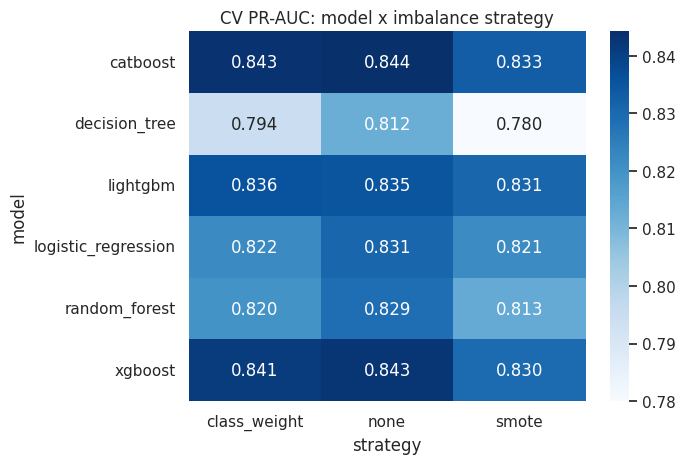

In [3]:
piv = comp[~comp.tuned].pivot(index='model', columns='strategy', values='pr_auc')
sns.heatmap(piv, annot=True, fmt='.3f', cmap='Blues'); plt.title('CV PR-AUC: model x imbalance strategy'); plt.show()

**Reading:** 'no imbalance handling' and 'class weights' tie on PR-AUC (threshold-free ranking quality), while **SMOTE is slightly worse for every model** - synthetic samples do not improve ranking here. CatBoost, XGBoost and LightGBM lead (~0.84); logistic regression is only ~0.01 behind, a strong interpretable baseline; the single decision tree is weakest.

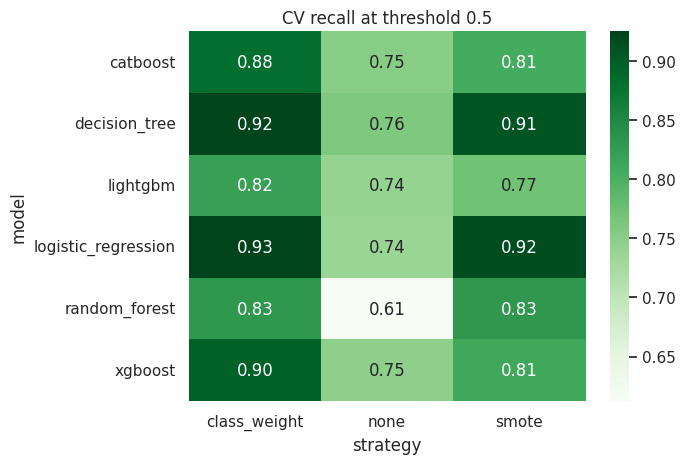

In [4]:
rec = comp[~comp.tuned].pivot(index='model', columns='strategy', values='recall')
sns.heatmap(rec, annot=True, fmt='.2f', cmap='Greens'); plt.title('CV recall at threshold 0.5'); plt.show()

**Reading:** with no imbalance handling, recall at 0.5 is clearly lower; class weights and SMOTE raise it - at the cost of precision. This is exactly why we also tune the threshold.

## 2. Selected model

In [5]:
print('Model   :', meta['model_name'])
print('Strategy:', meta['strategy'], '| tuned:', meta['tuned'])
print('Params  :', meta['params'])
print('CV PR-AUC:', round(meta['cv_metrics']['pr_auc'], 4))

Model   : catboost
Strategy: none | tuned: True
Params  : {'learning_rate': 0.05, 'l2_leaf_reg': 7, 'iterations': 200, 'depth': 6}
CV PR-AUC: 0.8498


## 3. Business-aware threshold
The threshold is the value that maximises expected net value on **out-of-fold training predictions** (the test set is not used to pick it).

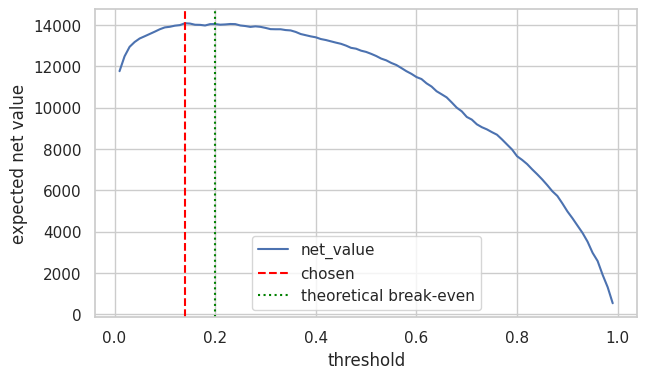

chosen threshold: 0.14 | theoretical break-even: 0.2


In [6]:
curve = pd.DataFrame(json.load(open(REP / 'threshold_curve.json')))
ax = curve.plot(x='threshold', y='net_value', figsize=(7, 4), legend=False)
ax.axvline(meta['threshold'], color='red', ls='--', label='chosen'); ax.axvline(meta['break_even_probability'], color='green', ls=':', label='theoretical break-even')
ax.set_ylabel('expected net value'); ax.legend(); plt.show()
print('chosen threshold:', meta['threshold'], '| theoretical break-even:', round(meta['break_even_probability'], 2))

**Reading:** theory says to act when `P(buy) x value x success > cost`, i.e. above the break-even probability. The empirical optimum sits close to it; the curve is flat around the optimum, so small differences are noise, not a problem.

## 4. Final test-set performance (touched once)

In [7]:
d, t = meta['test_metrics_at_0.5'], meta['test_metrics_at_threshold']
pd.DataFrame({'threshold 0.5': d, f"threshold {meta['threshold']:.2f}": t}).loc[['pr_auc','roc_auc','recall','precision','f1','accuracy','tp','fp','fn','tn']].round(4)

,threshold 0.5,threshold 0.14
pr_auc,0.8626,0.8626
roc_auc,0.9723,0.9723
recall,0.7719,0.9523
precision,0.8017,0.5876
f1,0.7865,0.7267
accuracy,0.9342,0.8875
tp,291.0000,359.0000
fp,72.0000,252.0000
fn,86.0000,18.0000
tn,1951.0000,1771.0000


In [8]:
v = meta['net_value_on_test']
pd.Series(v, name='expected net value on test').round(0)

chosen_threshold    3552.0
default_0.5         3276.0
flag_everyone      -1545.0
flag_nobody            0.0
Name: expected net value on test, dtype: float64

**Reading:** the chosen threshold catches far more buyers (recall ~0.95 vs ~0.77 at 0.5) at a precision cost, and yields the highest net value; nudging everyone loses money. Note accuracy *falls* (about 88.8% vs 93.4% at 0.5) exactly when the model becomes more useful for the business, and the 'nobody buys' baseline already scores 84.3% while finding zero buyers - accuracy is the wrong yardstick here.

## 5. Ablation: how much do we depend on `PageValues`?

In [9]:
abl = meta['ablation_page_values']
print('CV PR-AUC with PageValues   :', round(meta['cv_metrics']['pr_auc'], 3))
print('CV PR-AUC without PageValues:', round(abl['cv_pr_auc'], 3))
print('Test recall without @0.5    :', round(abl['test']['recall'], 3))

CV PR-AUC with PageValues   : 0.85
CV PR-AUC without PageValues: 0.529
Test recall without @0.5    : 0.411


**Finding (important):** removing `PageValues` drops PR-AUC from ~0.85 to ~0.53. The model is accurate mainly because `PageValues` reveals that a visitor has already reached revenue pages. Practical consequences:
- Use the **full model late in the session** (cart/checkout stage) to decide on last-minute nudges.
- For **early** scoring, train the early variant (`--no-page-values`) and accept a much weaker model.
- This trade-off, not the headline score, is the honest story to tell stakeholders.

## Takeaways
1. Boosted trees are best by PR-AUC; differences between the top models are small.
2. Imbalance strategies mostly change recall/precision at a fixed threshold.
3. Threshold chosen by business value, not 0.5.
4. Strong dependence on `PageValues` is documented and quantified.